# Compression examples
In this notebook we compare constraints on cosmological parameters obtained with different types of compressions (shapefit, direct).
Notebooks bao_examples.ipynb, fs_shapefit_examples.ipynb & fs_direct_examples.ipynb must be run first to produce the samples needed in this notebook.

## BAO compression
As a warm-up, what constraints on $\Omega_m$ do we obtain from an isotropic BAO fit?

In [1]:
from desilike.samples import MCSamples
from desilike import setup_logging

setup_logging()
z = 1.
# Chain produced by bao_examples.ipynb (isotropic BAO sampling section)
chain = MCSamples.read('_tests/chain_bao/samples_1.h5').remove_burnin(0.3)


In [2]:
import numpy as np

from desilike.theories.primordial_cosmology import CosmoprimoCosmology
from desilike.observables.galaxy_clustering import BAOCompressionObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike import build, get_params, Parameter

parameters = ['qiso']
data = [chain.mean(param) for param in parameters]
covariance = np.atleast_2d(np.asarray(chain.covariance(parameters)))

# Vary Omega_m only (see bao_examples): with all base cosmological parameters free,
# a single qiso measurement would only constrain a wide degeneracy band
cosmo_calc = CosmoprimoCosmology(params=[Parameter('Omega_m', value=0.3137, prior=dict(limits=[0.05, 0.9]),
                                                   ref=dict(dist='norm', loc=0.3137, scale=0.01), latex=r'\Omega_{m}')],
                                 fiducial='DESI')
observable = BAOCompressionObservable(data=data, covariance=covariance, parameters=parameters, z=z, fiducial='DESI', cosmo=cosmo_calc)
likelihood = ObservablesGaussianLikelihood(observables=[observable])

In [3]:
# A bit of emulation, to speed up inference: each direct evaluation runs a full Boltzmann
# computation. We emulate the theory the observable wraps -- its scalar outputs (qiso, qpar,
# ...) are its pytree state, which is exactly what a `CalculatorEmulator` predicts -- and swap
# the emulated calculator back in, so the observable keeps its data bookkeeping.
from desilike.emulators import Emulator, Space

# A `Space` says where the emulator must be accurate. `Space(observable.theory)` would read the
# box off each parameter's `ref`, but that `ref` is a normal distribution with no finite limits,
# so state the box explicitly -- amply wider than the posterior, since outside it the emulator
# predicts NaN (i.e. -inf posterior) rather than extrapolating.
emulator = Emulator(observable.theory, Space(bounds={'Omega_m': (0.2, 0.45)}), budget=4)
print(len(emulator.nodes()), 'nodes')
emulator.train()
#observable.update(theory=emulator.to_calculator())
likelihood = ObservablesGaussianLikelihood(observables=[observable], covariance=covariance)

5 nodes
[000001.43]  10-10 12:50  Emulator                     INFO     training on 5 nodes over 1 parameters; 0 handled exactly
[000001.43]  10-10 12:50  Emulator                     INFO     node box: Omega_m [0.2, 0.45]
[000001.43]  10-10 12:50  TrainingSet                  INFO     5/5 nodes to evaluate; no checkpoint (nothing is resumable)
[000002.03]  10-10 12:50  TrainingSet                  INFO     training complete (5/5 nodes)


In [4]:
from desilike import Sampler, Posterior
from desilike.samplers import Emcee

# Sample the posterior = likelihood + priors: wrap the likelihood in Posterior
sampler = Sampler(build(Posterior(likelihood)), kernel=Emcee(), rng=42)
samples_bao = sampler.run(min_steps=2000, max_steps=5000, gelman_rubin=1.02)

[000002.92]  10-10 12:50  EnsembleSampler              INFO     Varied parameters: ['Omega_m']
[000119.43]  10-10 12:52  Emcee                        INFO     total likelihood evaluations: 1196
[000119.50]  10-10 12:52  EnsembleSampler              INFO     Diagnostics:
[000119.50]  10-10 12:52  EnsembleSampler              INFO     Gelman-Rubin: 1.14
[000119.50]  10-10 12:52  EnsembleSampler              INFO     1.14 >= 1.02 (not passed)
[000119.50]  10-10 12:52  EnsembleSampler              INFO     Geweke: 0.319
[000119.51]  10-10 12:52  EnsembleSampler              INFO     Effective Sample Size: 101
[000234.89]  10-10 12:54  Emcee                        INFO     total likelihood evaluations: 2396
[000234.96]  10-10 12:54  EnsembleSampler              INFO     Diagnostics:
[000234.96]  10-10 12:54  EnsembleSampler              INFO     Gelman-Rubin: 1
[000234.96]  10-10 12:54  EnsembleSampler              INFO     1 < 1.02 (passed)
[000234.96]  10-10 12:54  EnsembleSampler        

Removed no burn in


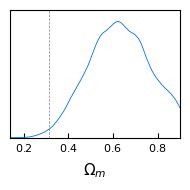

In [5]:
from desilike.samples import plotting
from cosmoprimo.fiducial import DESI

fiducial = DESI()
chain_bao = samples_bao.remove_burnin(0.4)
plotting.plot_triangle(chain_bao, markers={'Omega_m': fiducial.Omega0_m})

## ShapeFit compression
Now turn to shapefit compression.

In [6]:
from desilike.theories.galaxy_clustering import ShapeFitSpectrum2Template, ShapeFitTheory
help(ShapeFitSpectrum2Template)
help(ShapeFitTheory)

Help on class ShapeFitSpectrum2Template in module desilike.theories.galaxy_clustering.template:

class ShapeFitSpectrum2Template(Spectrum2Template)
 |  ShapeFitSpectrum2Template(k=None, z=1.0, fiducial='DESI', with_now='peakaverage', only_now=False, apmode='qparqper', eta=0.3333333333333333, kp=0.03, a=0.6, params=None)
 |
 |  ShapeFit power spectrum template.
 |
 |  Multiplies the fiducial power spectrum by a k-dependent tilt factor controlled by ``dm``, ``dn`` and ``dA``.
 |
 |  Parameters
 |  ----------
 |  k : array, default=None
 |      Wavenumbers [h/Mpc]. Defaults to np.logspace(-3, 1, 400).
 |  z : float, default=1.
 |      Effective redshift.
 |  fiducial : str, tuple, dict, or cosmoprimo.Cosmology, default='DESI'
 |      Fiducial cosmology.
 |  with_now : str or False, default='peakaverage'
 |      Engine for the no-wiggle power spectrum ('peakaverage', 'wallish2018').
 |      Set to False to skip (pknow_dd is set equal to pk_dd).
 |  only_now : bool, default=False
 |      Re

In [7]:
# `ShapeFitTheory` and `ShapeFitCompressionObservable` now ship with desilike (they were
# defined by hand in this notebook while the refactor was in flight).
from desilike.theories.galaxy_clustering import ShapeFitTheory
from desilike.observables.galaxy_clustering import ShapeFitCompressionObservable

In [8]:
import numpy as np
# Chain produced by fs_shapefit_examples.ipynb
chain = MCSamples.read('_tests/chain_fs_shapefit/samples_1.h5').remove_burnin(0.3)

parameters = ['qpar', 'qper', 'df', 'dm']
data = [chain.mean(param) for param in parameters]
covariance = np.asarray(chain.covariance(parameters))
observable = ShapeFitCompressionObservable(data=data, covariance=covariance, parameters=parameters, z=z, fiducial='DESI')
params = get_params(observable)
params['omega_b'].update(fixed=True)
params['n_s'].update(fixed=True)

# A bit of emulation, to speed up inference: each direct evaluation runs a full Boltzmann
# computation. We emulate the theory the observable wraps -- its scalar outputs (qpar, qper,
# dm, df, ...) are its pytree state, which is exactly what a `CalculatorEmulator` predicts --
# and swap the emulated calculator back in, so the observable keeps its data bookkeeping.
emulator = Emulator(observable.theory, Space(bounds={'h': (0.60, 0.75), 'omega_cdm': (0.10, 0.14), 'logA': (2.9, 3.2)}), budget=3)
print(len(emulator.nodes()), 'nodes')
emulator.train()
observable.update(theory=emulator.to_calculator())
likelihood = ObservablesGaussianLikelihood(observables=[observable], covariance=covariance)

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


57 nodes
[001157.86]  10-10 13:09  Emulator                     INFO     training on 57 nodes over 3 parameters; 0 handled exactly
[001157.86]  10-10 13:09  Emulator                     INFO     node box: h [0.6, 0.75], omega_cdm [0.1, 0.14], logA [2.9, 3.2]
[001157.86]  10-10 13:09  TrainingSet                  INFO     57/57 nodes to evaluate; no checkpoint (nothing is resumable)
[001228.55]  10-10 13:10  TrainingSet                  INFO     50/57 nodes
[001238.44]  10-10 13:11  TrainingSet                  INFO     training complete (57/57 nodes)


In [9]:
from desilike.samplers import Zeus, Emcee

sampler = Sampler(build(Posterior(likelihood)), kernel=Zeus(), rng=42)
samples_shapefit = sampler.run(min_steps=1000, max_steps=3000, gelman_rubin=1.01)

[001240.23]  10-10 13:11  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA']


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/desilike/refactor-jax/lib/python3.12/site-packages/desilike/samplers/zeus.py:67: UserWarning: Zeus does not support random seeds. Results are not deterministic.
  warnings.warn('Zeus does not support random seeds. Results are not deterministic.')


[001241.43]  10-10 13:11  root                         INFO     Initialising ensemble of 12 walkers...
[001249.80]  10-10 13:11  EnsembleSampler              INFO     Diagnostics:
[001249.81]  10-10 13:11  EnsembleSampler              INFO     Gelman-Rubin: 1.03
[001249.81]  10-10 13:11  EnsembleSampler              INFO     1.03 >= 1.01 (not passed)
[001249.81]  10-10 13:11  EnsembleSampler              INFO     Geweke: 0.156
[001249.81]  10-10 13:11  EnsembleSampler              INFO     Effective Sample Size: 520
[001249.81]  10-10 13:11  root                         INFO     Initialising ensemble of 12 walkers...
[001251.80]  10-10 13:11  EnsembleSampler              INFO     Diagnostics:
[001251.81]  10-10 13:11  EnsembleSampler              INFO     Gelman-Rubin: 1.01
[001251.81]  10-10 13:11  EnsembleSampler              INFO     1.01 < 1.01 (passed)
[001251.82]  10-10 13:11  EnsembleSampler              INFO     Geweke: 0.119
[001251.82]  10-10 13:11  EnsembleSampler           

Removed no burn in
Removed no burn in


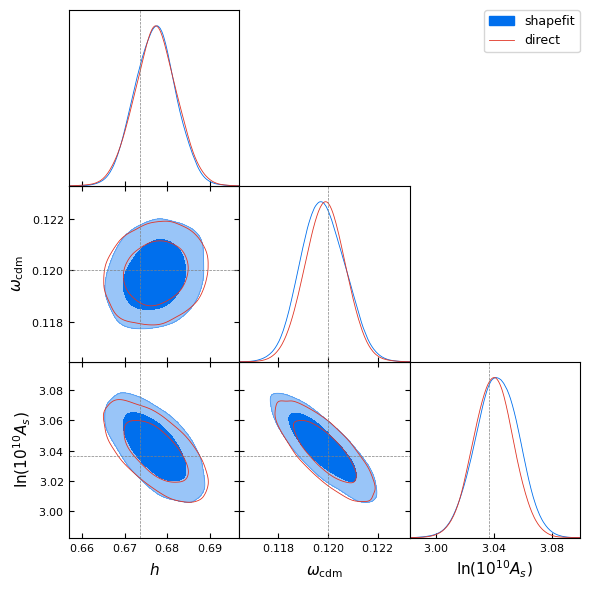

In [10]:
from desilike.samples import plotting

chain_shapefit = samples_shapefit.remove_burnin(0.5)
# Chain produced by fs_direct_examples.ipynb (omega_b and n_s fixed there, so it only shows
# on the h/omega_cdm/logA subspace)
chain_direct = MCSamples.read('_tests/chain_fs_direct/samples_1.h5').remove_burnin(0.5)
plotting.plot_triangle([chain_shapefit, chain_direct], 
                       filled=True, labels=['shapefit', 'direct'],
                       params = ['omega_b', 'h', 'omega_cdm', 'n_s', 'logA'],
                       markers={'h': fiducial.h, 'omega_cdm': fiducial.Omega0_cdm * fiducial.h**2,
                                'logA': np.log(10**10 * fiducial.A_s), 'n_s': fiducial.n_s})

# Shapefit interpretation with free dn

In [12]:
import numpy as np
# Chain produced by fs_shapefit_examples.ipynb
chain = MCSamples.read('_tests/chain_fs_shapefit_dn/samples_1.h5').remove_burnin(0.3)

parameters = ['qpar', 'qper', 'df', 'dm', 'dn']
data = [chain.mean(param) for param in parameters]
covariance = np.asarray(chain.covariance(parameters))
observable = ShapeFitCompressionObservable(data=data, covariance=covariance, parameters=parameters, z=z, fiducial='DESI')
params = get_params(observable)
for name in ['omega_b', 'n_s']: params[name].update(fixed=True)

# A bit of emulation, to speed up inference: each direct evaluation runs a full Boltzmann
# computation. We emulate the theory the observable wraps -- its scalar outputs (qpar, qper,
# dm, df, ...) are its pytree state, which is exactly what a `CalculatorEmulator` predicts --
# and swap the emulated calculator back in, so the observable keeps its data bookkeeping.
emulator = Emulator(observable.theory, Space(bounds={'h': (0.60, 0.75), 'omega_cdm': (0.10, 0.14), 'logA': (2.9, 3.2)}), budget=3)
print(len(emulator.nodes()), 'nodes')
emulator.train()
observable.update(theory=emulator.to_calculator())
likelihood = ObservablesGaussianLikelihood(observables=[observable], covariance=covariance)

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


57 nodes
[002096.41]  10-10 13:25  Emulator                     INFO     training on 57 nodes over 3 parameters; 0 handled exactly
[002096.41]  10-10 13:25  Emulator                     INFO     node box: h [0.6, 0.75], omega_cdm [0.1, 0.14], logA [2.9, 3.2]
[002096.41]  10-10 13:25  TrainingSet                  INFO     57/57 nodes to evaluate; no checkpoint (nothing is resumable)
[002167.85]  10-10 13:26  TrainingSet                  INFO     50/57 nodes
[002177.73]  10-10 13:26  TrainingSet                  INFO     training complete (57/57 nodes)


In [16]:
from desilike.samplers import Zeus

sampler = Sampler(build(Posterior(likelihood)), kernel=Zeus(), rng=42)
samples_shapefit_dn = sampler.run(min_steps=1000, max_steps=3000, gelman_rubin=1.01)

[002294.00]  10-10 13:28  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA']
[002294.73]  10-10 13:28  root                         INFO     Initialising ensemble of 12 walkers...
[002302.67]  10-10 13:28  EnsembleSampler              INFO     Diagnostics:
[002302.68]  10-10 13:28  EnsembleSampler              INFO     Gelman-Rubin: 1.01
[002302.69]  10-10 13:28  EnsembleSampler              INFO     1.01 >= 1.01 (not passed)
[002302.69]  10-10 13:28  EnsembleSampler              INFO     Geweke: 0.0925
[002302.69]  10-10 13:28  EnsembleSampler              INFO     Effective Sample Size: 639
[002302.69]  10-10 13:28  root                         INFO     Initialising ensemble of 12 walkers...
[002305.27]  10-10 13:28  EnsembleSampler              INFO     Diagnostics:
[002305.28]  10-10 13:28  EnsembleSampler              INFO     Gelman-Rubin: 1
[002305.28]  10-10 13:28  EnsembleSampler              INFO     1 < 1.01 (passed)
[002305.28]  10-10 13:28 

Removed no burn in
Removed no burn in
Removed no burn in


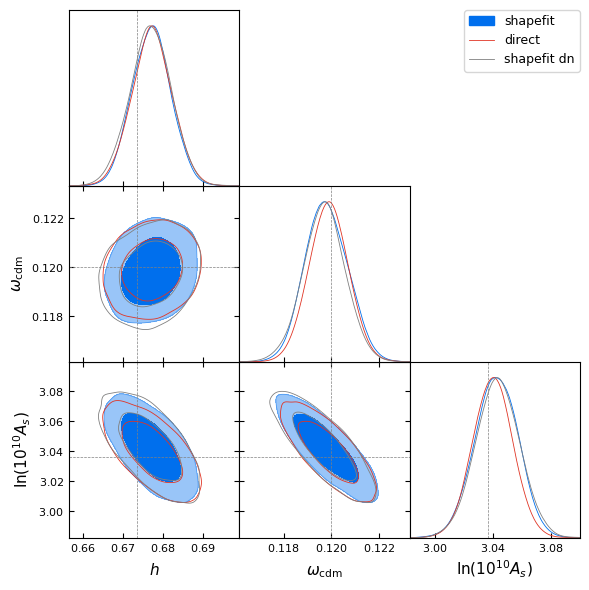

In [18]:
from desilike.samples import plotting

# Chain produced by fs_direct_examples.ipynb (omega_b and n_s fixed there, so it only shows
# on the h/omega_cdm/logA subspace)
chain_direct = MCSamples.read('_tests/chain_fs_direct/samples_1.h5').remove_burnin(0.5)
plotting.plot_triangle([chain_shapefit, chain_direct, samples_shapefit_dn], ['h', 'omega_cdm', 'logA', 'n_s'],
                       filled=True, labels=['shapefit', 'direct', 'shapefit dn'],
                       markers={'h': fiducial.h, 'omega_cdm': fiducial.Omega0_cdm * fiducial.h**2,
                                'logA': np.log(10**10 * fiducial.A_s), 'n_s': fiducial.n_s})

## Now interpret shapefit P with free $dA$

In [23]:
import numpy as np
# Chain produced by fs_shapefit_examples.ipynb
chain = MCSamples.read('_tests/chain_fs_shapefit_Ap/samples_1.h5').remove_burnin(0.3)

parameters = ['qpar', 'qper', 'df', 'dm', 'dA']
data = [chain.mean(param) for param in parameters]
covariance = np.asarray(chain.covariance(parameters))
observable = ShapeFitCompressionObservable(data=data, covariance=covariance, parameters=parameters, z=z, fiducial='DESI')
params = get_params(observable)
for name in ['omega_b', 'n_s']: params[name].update(fixed=True)

# A bit of emulation, to speed up inference: each direct evaluation runs a full Boltzmann
# computation. We emulate the theory the observable wraps -- its scalar outputs (qpar, qper,
# dm, df, ...) are its pytree state, which is exactly what a `CalculatorEmulator` predicts --
# and swap the emulated calculator back in, so the observable keeps its data bookkeeping.
emulator = Emulator(observable.theory, Space(bounds={'h': (0.60, 0.75), 'omega_cdm': (0.10, 0.14), 'logA': (2.9, 3.2)}), budget=3)
print(len(emulator.nodes()), 'nodes')
emulator.train()
observable.update(theory=emulator.to_calculator())
likelihood = ObservablesGaussianLikelihood(observables=[observable], covariance=covariance)

57 nodes
[002095.79]  09-17 00:40  Emulator                     INFO     training on 57 nodes over 3 parameters; 0 handled exactly
[002095.79]  09-17 00:40  Emulator                     INFO     node box: h [0.6, 0.75], omega_cdm [0.1, 0.14], logA [2.9, 3.2]
[002095.80]  09-17 00:40  TrainingSet                  INFO     57/57 nodes to evaluate; no checkpoint (nothing is resumable)
[002166.55]  09-17 00:42  TrainingSet                  INFO     50/57 nodes
[002176.51]  09-17 00:42  TrainingSet                  INFO     training complete (57/57 nodes)


In [24]:
from desilike.samplers import Zeus

sampler = Sampler(build(Posterior(likelihood)), kernel=Zeus(), rng=42)
samples_shapefit_dA = sampler.run(min_steps=1000, max_steps=3000, gelman_rubin=1.01)

[002176.71]  09-17 00:42  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA']
[002177.55]  09-17 00:42  root                         INFO     Initialising ensemble of 12 walkers...
[002186.42]  09-17 00:42  EnsembleSampler              INFO     Diagnostics:
[002186.43]  09-17 00:42  EnsembleSampler              INFO     Gelman-Rubin: 1.01
[002186.43]  09-17 00:42  EnsembleSampler              INFO     1.01 >= 1.01 (not passed)
[002186.43]  09-17 00:42  EnsembleSampler              INFO     Geweke: 0.0833
[002186.43]  09-17 00:42  EnsembleSampler              INFO     Effective Sample Size: 620
[002186.43]  09-17 00:42  root                         INFO     Initialising ensemble of 12 walkers...
[002187.59]  09-17 00:42  EnsembleSampler              INFO     Diagnostics:
[002187.60]  09-17 00:42  EnsembleSampler              INFO     Gelman-Rubin: 1.01
[002187.60]  09-17 00:42  EnsembleSampler              INFO     1.01 < 1.01 (passed)
[002187.60]  09-17 

Removed no burn in
Removed no burn in
Removed no burn in


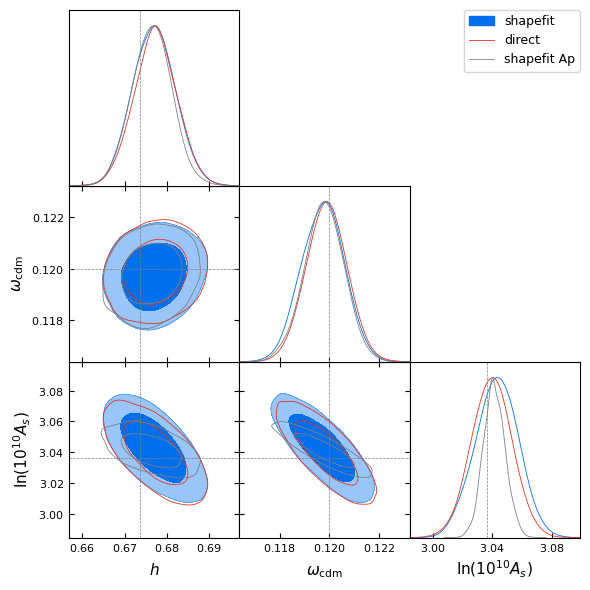

In [25]:
from desilike.samples import plotting

chain_shapefit_Ap = samples_shapefit_dA.remove_burnin(0.5)

# Chain produced by fs_direct_examples.ipynb (omega_b and n_s fixed there, so it only shows
# on the h/omega_cdm/logA subspace)
chain_direct = MCSamples.read('_tests/chain_fs_direct/samples_1.h5').remove_burnin(0.5)
plotting.plot_triangle([chain_shapefit, chain_direct, chain_shapefit_Ap], ['h', 'omega_cdm', 'logA', 'n_s'],
                       filled=True, labels=['shapefit', 'direct', 'shapefit Ap'],
                       markers={'h': fiducial.h, 'omega_cdm': fiducial.Omega0_cdm * fiducial.h**2,
                                'logA': np.log(10**10 * fiducial.A_s), 'n_s': fiducial.n_s})

## Now interpret shapefit with $dA$ on the bispectrum

In [17]:
from desilike.observables.galaxy_clustering import ShapeFitCompressionObservable
import numpy as np
# Chain produced by fs_shapefit_examples.ipynb
chain = MCSamples.read('_tests/chain_fs_shapefit_Ap_bispec/samples_1.h5').remove_burnin(0.3)

parameters = ['qpar', 'qper', 'df', 'dm', 'dA']
data = [chain.mean(param) for param in parameters]
covariance = np.asarray(chain.covariance(parameters))
observable = ShapeFitCompressionObservable(data=data, covariance=covariance, parameters=parameters, z=z, fiducial='DESI')
params = get_params(observable)
for name in ['omega_b', 'n_s']: params[name].update(fixed=True)

# A bit of emulation, to speed up inference: each direct evaluation runs a full Boltzmann
# computation. We emulate the theory the observable wraps -- its scalar outputs (qpar, qper,
# dm, df, ...) are its pytree state, which is exactly what a `CalculatorEmulator` predicts --
# and swap the emulated calculator back in, so the observable keeps its data bookkeeping.
emulator = Emulator(observable.theory, Space(bounds={'h': (0.60, 0.75), 'omega_cdm': (0.10, 0.14), 'logA': (2.9, 3.2)}), budget=3)
print(len(emulator.nodes()), 'nodes')
emulator.train()
observable.update(theory=emulator.to_calculator())
likelihood = ObservablesGaussianLikelihood(observables=[observable], covariance=covariance)

57 nodes
[000522.53]  09-17 00:14  Emulator                     INFO     training on 57 nodes over 3 parameters; 0 handled exactly
[000522.53]  09-17 00:14  Emulator                     INFO     node box: h [0.6, 0.75], omega_cdm [0.1, 0.14], logA [2.9, 3.2]
[000522.53]  09-17 00:14  TrainingSet                  INFO     57/57 nodes to evaluate; no checkpoint (nothing is resumable)
[000592.51]  09-17 00:15  TrainingSet                  INFO     50/57 nodes
[000602.41]  09-17 00:15  TrainingSet                  INFO     training complete (57/57 nodes)


In [18]:
from desilike.samplers import Zeus

sampler = Sampler(build(Posterior(likelihood)), kernel=Zeus(), rng=42)
samples_shapefit_bispec = sampler.run(min_steps=1000, max_steps=3000, gelman_rubin=1.01)

[000602.61]  09-17 00:15  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA']


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/desilike/refactor-jax/lib/python3.12/site-packages/desilike/samplers/zeus.py:67: UserWarning: Zeus does not support random seeds. Results are not deterministic.
  warnings.warn('Zeus does not support random seeds. Results are not deterministic.')


[000603.43]  09-17 00:16  root                         INFO     Initialising ensemble of 12 walkers...
[000612.97]  09-17 00:16  EnsembleSampler              INFO     Diagnostics:
[000612.98]  09-17 00:16  EnsembleSampler              INFO     Gelman-Rubin: 1.01
[000612.98]  09-17 00:16  EnsembleSampler              INFO     1.01 >= 1.01 (not passed)
[000612.98]  09-17 00:16  EnsembleSampler              INFO     Geweke: 0.163
[000612.98]  09-17 00:16  EnsembleSampler              INFO     Effective Sample Size: 610
[000612.98]  09-17 00:16  root                         INFO     Initialising ensemble of 12 walkers...
[000614.17]  09-17 00:16  EnsembleSampler              INFO     Diagnostics:
[000614.18]  09-17 00:16  EnsembleSampler              INFO     Gelman-Rubin: 1
[000614.18]  09-17 00:16  EnsembleSampler              INFO     1 < 1.01 (passed)
[000614.18]  09-17 00:16  EnsembleSampler              INFO     Geweke: 0.125
[000614.18]  09-17 00:16  EnsembleSampler              INF

Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in


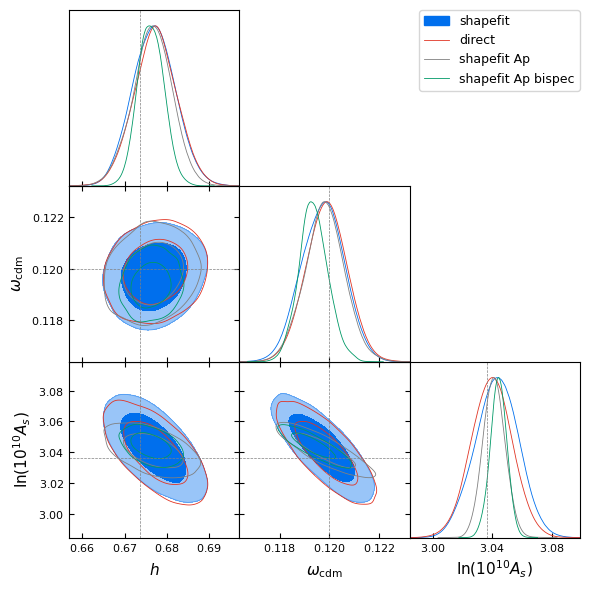

In [19]:
from desilike.samples import plotting

chain_shapefit_Ap_bispec = samples_shapefit_bispec.remove_burnin(0.5)

# Chain produced by fs_direct_examples.ipynb (omega_b and n_s fixed there, so it only shows
# on the h/omega_cdm/logA subspace)
chain_direct = MCSamples.read('_tests/chain_fs_direct/samples_1.h5').remove_burnin(0.5)
plotting.plot_triangle([chain_shapefit, chain_direct, chain_shapefit_Ap, chain_shapefit_Ap_bispec], ['h', 'omega_cdm', 'logA', 'n_s'],
                       filled=True, labels=['shapefit', 'direct', 'shapefit Ap', 'shapefit Ap bispec'],
                       markers={'h': fiducial.h, 'omega_cdm': fiducial.Omega0_cdm * fiducial.h**2,
                                'logA': np.log(10**10 * fiducial.A_s), 'n_s': fiducial.n_s})

Removed no burn in
Removed no burn in
[000617.99]  09-17 00:16  root                         WARNING  auto bandwidth for h very small or failed (h=0.0012866713740307028,N_eff=3264.0). Using fallback (h=0.027356760968328477)
[000618.01]  09-17 00:16  root                         WARNING  auto bandwidth for omega_cdm very small or failed (h=0.000942737771011591,N_eff=3264.0). Using fallback (h=0.024117327148336514)
[000618.02]  09-17 00:16  root                         WARNING  auto bandwidth for logA very small or failed (h=0.0008153057531869429,N_eff=3264.0). Using fallback (h=0.03003845336113985)
[000618.10]  09-17 00:16  root                         WARNING  fine_bins_2D not large enough for optimal density: h, omega_cdm
[000618.20]  09-17 00:16  root                         WARNING  fine_bins_2D not large enough for optimal density: h, logA
[000618.29]  09-17 00:16  root                         WARNING  fine_bins_2D not large enough for optimal density: omega_cdm, logA


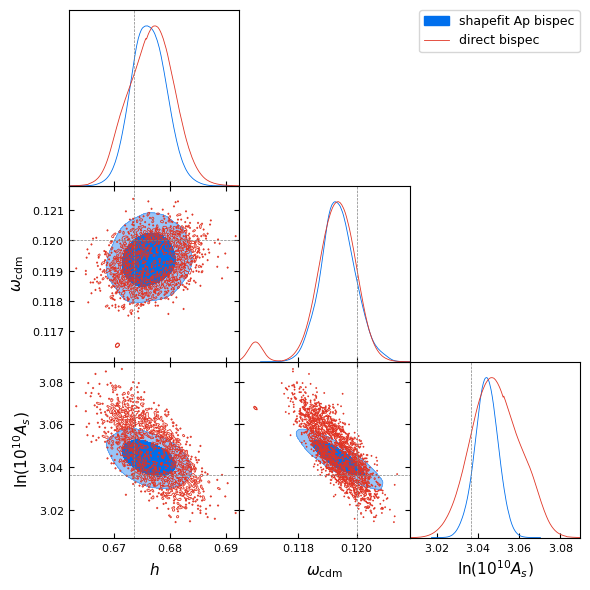

In [20]:
from desilike.samples import plotting

chain_shapefit_Ap_bispec = samples_shapefit_bispec.remove_burnin(0.5)

# Chain produced by fs_direct_examples.ipynb (omega_b and n_s fixed there, so it only shows
# on the h/omega_cdm/logA subspace)
chain_direct_bispec = MCSamples.read('_tests/chain_fs_FM_bispec/samples_1.h5').remove_burnin(0.5)[::50]
plotting.plot_triangle([chain_shapefit_Ap_bispec, chain_direct_bispec], ['h', 'omega_cdm', 'logA', 'n_s'],
                       filled=True, labels=['shapefit Ap bispec', 'direct bispec'],
                       markers={'h': fiducial.h, 'omega_cdm': fiducial.Omega0_cdm * fiducial.h**2,
                                'logA': np.log(10**10 * fiducial.A_s), 'n_s': fiducial.n_s})